# **SKYSOLVE CAPSTONE PROJECT**

# **1. Business Understanding**

Airlines receive huge volumes of passenger feedback aboutdelays, staff, food, value for money and overall satisfaction. Reading it by hand is slow andexpensive, and unread complaints repeat and damage the airline's reputation.

Support teams also struggle with large volumes of incomingtickets. Slow or wrong classification delays replies, frustrates customers and overloadssupport staff. Classic machine learning models struggle with messy, complex text.

Long reviews tell us what passengers think after the trip. Shorttweets tell us what they complain about in the moment. By learning topics and sentimentfrom reviews and testing them on tweets, we can help an airline understand complaintsand respond faster.

---

## **1.1 Business Objectives**

* Predict whether a passenger recommends an airline, and show whether deep learning can beat a simple baseline machine learning model.

* Identify clear, recurring themes of satisfaction and dissatisfaction in airline service industry.

* Test whether those themes and the sentiment model carry over to short customer tweets.

* Classify incoming complaints and suggest a grounded reply plus a short summary of the conversation.

* Turn the results into insights an airline could use to prioritize improvements.
---

## **1.2 Stakeholders**
Airline management and staff (operational issues, service decisions),customer support teams (faster, more consistent replies), travel agents and operators(customer needs), regulators (service standards seen through customer experience), andpassengers (indirect benefit).

# **2. Data Understanding **




| Category | Skytrax Airline Reviews | Twitter Customer Support (Airline Subset) |
|---|---|---|
| **Source** | Mendeley Data | Kaggle "Customer Support on Twitter" (twcs.csv) |
| **Size we hold** | 64,740 rows, 19 columns, 109 airlines | 370,863 rows, 7 columns, 9 airline support accounts |
| **Period** | Jan 2015 to Aug 2025 | Almost all Oct to Dec 2017 |
| **Content** | Review text, 1 to 10 rating, subratings, recommend yes/no | 198,017 customer tweets and 172,846 airline replies |
| **Labels** | Recommended: 39,944 no, 24,795 yes | None. We hand-label 300. |
| **Text style** | Long, written after the trip | Short, written mid-complaint |
| **Used for** | Parts 1 and 2 (training and testing) | Subunit 3B and Part 3 (transfer test, retrieval) |


In [1]:
# !pip install nltk

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import nltk
import string
from collections import Counter
from nltk.tokenize import word_tokenize,sent_tokenize,RegexpTokenizer
from nltk.corpus import stopwords,wordnet
from nltk.stem import PorterStemmer,WordNetLemmatizer,SnowballStemmer
from nltk.probability import FreqDist
from nltk import pos_tag
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.util import ngrams,bigrams
from sklearn.feature_extraction.text import CountVectorizer,TfidfVectorizer


In [3]:
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('vader_lexicon')


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


True

## **2.1 Data Loading**

For data loading, use a method that ensures access of the dataset without loading from local drive as the data can be bulky.

Uploading Dataset directly from the computer is an unreliable approach since you need to download a copy of the dataset to your local drive to repeatedly upload it before inspecting. It is however okay if the computer can handle it.

Using google colab **"Drive Mount"** imports Google Drive into this Colab notebook and enables access of the dataset stored in the Google Drive as if it is part of the local file system. This method does not require repeat uploading of dataset to colab.

A **shareable google drive link** means that anyone with the link can be able to view, edit, or comment on both the notebook and the dataset depending on the share permission set by the author.

We uploaded "Skytrax Airline Review Data.csv" to a **github repository** and the github raw link that can be used as an alternative to load the data remotely.

The tweets dataset is very huge and content intensive and as such, can crash on local drive, and could not upload to github even after zipping. As such, one can use a kaggle link with the same dataset to load the data on the notebook environment.

In [4]:
#load the dataset from local drive

# df_airline = pd.read_csv("datasets/Skytrax Airline Review Data.csv")
# df_tweets = pd.read_csv("datasets/twcs.csv")

In [5]:
## !NOT THE BEST APPROACH TO LOADING THIS DATASETS. THEY ARE LARGE.
# # Upload dataset directly from the computer to google colab. The tweets data is quite bulky!
# # Uncomment the code below

# from google.colab import files
# uploaded = files.upload()

# df_airline = pd.read_csv("Skytrax Airline Review Data.csv")
# print("✓ Airlines Reviews Dataset loaded successfully!")

# df_tweets = pd.read_csv("twcs.csv")
# print("\n ✓  Tweets Dataset loaded successfully!")


In [6]:
# # UPLOAD THE DATA FILES INTO YOUR GOOGLE DRIVE FOR THIS METHOD to load the datasets from google drive mount

# from google.colab import drive
# drive.mount("/content/drive")

# df = pd.read_csv("/content/drive/MyDrive/Skysolve_Project/datasets/Skytrax Airline Review Data.csv")
# print("✓ Airlines Reviews Dataset loaded successfully!")

# df_tweets = pd.read_csv("/content/drive/MyDrive/Skysolve_Project/datasets/twcs.csv")
# print("\n ✓  Tweets Dataset loaded successfully!")

In [7]:
# # Load and access the datasets using a shareable google drive link
# # Original google shareable link for the airlines review dataset is: https://drive.google.com/file/d/1c0ULRVTqMg2_dIQwB_llA7kLbnwoqJo6/view?usp=sharing
# # Convert the google link to a downloadable url: https://drive.google.com/uc?id=1c0ULRVTqMg2_dIQwB_llA7kLbnwoqJo6
# # Uncomment the code below for results

# airline_url = "https://drive.google.com/uc?id=1c0ULRVTqMg2_dIQwB_llA7kLbnwoqJo6"
# df_airline = pd.read_csv(airline_url)
# print("✓ Airlines Reviews Dataset loaded successfully!")


# # Original google shareable link for the tweets dataset is: https://drive.google.com/file/d/1fwJLuf9VMqSRk2dPo2LNZBYm4a-C44fm/view?usp=sharing
# # Convert the google link to a downloadable url: https://drive.google.com/uc?id=1fwJLuf9VMqSRk2dPo2LNZBYm4a-C44fm
# # Uncomment the code below for results

# tweets_url = "https://drive.google.com/uc?id=1fwJLuf9VMqSRk2dPo2LNZBYm4a-C44fm"
# df_tweets = pd.read_csv(tweets_url)
# print("\n ✓  Tweets Dataset loaded successfully!")

In [8]:
# # Load and access Skytrax Airline Review zipped data file using github raw link

# # GitHub raw ZIP file URL
url = "https://raw.githubusercontent.com/nyagayamonica/Skytrax_Airline_Review_Data/main/Skytrax%20Airline%20Review%20Data.zip"

# # Read ZIP file directly
df_airline = pd.read_csv(url, compression="zip")

print("✓ Dataset loaded successfully!")
print("Airline dataset shape:", df_airline.shape)

✓ Dataset loaded successfully!
Airline dataset shape: (64740, 19)


In [9]:
# # Load and access "the tweets dataset" from kaggle

# # Install kaggle
!pip -q install kagglehub
import kagglehub

# # import kagglehub
from pathlib import Path

# # Download dataset into the notebook environment
dataset_path = kagglehub.dataset_download("thoughtvector/customer-support-on-twitter")

# # Find the CSV
csv_path = next(Path(dataset_path).rglob("twcs.csv"))

# # Load the dataset
df_tweets = pd.read_csv(csv_path)

# print("✓ \n Tweets Dataset loaded successfully!")
print("Tweets dataset shape:", df_tweets.shape)

100%|██████████| 169M/169M [00:02<00:00, 84.0MB/s]

Extracting files...


Tweets dataset shape: (2811774, 7)


## **2.2 Data Inspection: Airline Reviews Dataset**

Data Inspection helps us understand the structure and quality of the data before cleaning.

We will examine the number of records,the number of columns,the column names, their data types,the number of missing rows,number of duplicated entries and a statistical summary.



In [10]:
#inspecting the top 5 rows
df_airline.head(5)

,review_date,over_all_rating,review_header,trip_verified,review_text,aircraft,type_of_traveller,seat_type,route,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,wifi__connectivity,value_for_money,recommended,airline_name
0,2025-08-04,1.0,"""showed zero empathy for passengers""",Trip Verified,My afternoon flight was delayed and eventuall...,NaN,business,economy_class,dubai_to_kochi,august_2025,1.0,2.0,2.0,2.0,1.0,1.0,1.0,no,spicejet
1,2025-07-21,2.0,"""Extremely dissatisfied""",Trip Verified,The flight was postponed 3 times with insuffi...,NaN,family_leisure,economy_class,pune_to_dubai,july_2025,1.0,3.0,NaN,NaN,3.0,NaN,2.0,no,spicejet
2,2025-04-19,2.0,"""Very bad experience""",Trip Verified,They will charge you for your hand baggage if...,NaN,business,economy_class,mumbai_to_kolkata,april_2025,3.0,3.0,3.0,NaN,1.0,NaN,2.0,no,spicejet
3,2025-03-12,1.0,“What a difficult airline”,Trip Verified,The flight was delayed from 15:20 to 16:25. I...,NaN,business,economy_class,"pune,_india_to_new_delhi,_india",march_2025,3.0,4.0,NaN,NaN,5.0,NaN,1.0,no,spicejet
4,2025-03-02,2.0,“Poor chaotic boarding”,Trip Verified,No crowd control and boarding was like cattle...,boeing_747,solo_leisure,economy_class,mumbai_to_new_delhi,march_2025,3.0,1.0,3.0,NaN,1.0,NaN,2.0,no,spicejet


In [11]:
#inspecting the bottom 5 columns
df_airline.tail(5)

,review_date,over_all_rating,review_header,trip_verified,review_text,aircraft,type_of_traveller,seat_type,route,date_flown,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,wifi__connectivity,value_for_money,recommended,airline_name
64735,2015-07-23,7.0,Gulf Air customer review,NaN,The plane from London to Bahrain was awful - ...,NaN,family_leisure,economy_class,london_to_chennai_via_bahrain,may_2015,3.0,3.0,3.0,4.0,4.0,NaN,5.0,yes,gulf-air
64736,2015-06-19,6.0,Gulf Air customer review,NaN,London to Bahrain on board an A330. Check in ...,a330/320,couple_leisure,economy_class,lhr_to_abu_dhabi_via_bahrain,june_2015,2.0,2.0,3.0,3.0,3.0,NaN,4.0,no,gulf-air
64737,2015-06-15,8.0,Gulf Air customer review,NaN,I had read many reviews regarding their new F...,a330,business,business_class,bangkok_to_london_via_bahrain,may_2015,4.0,5.0,4.0,3.0,4.0,NaN,5.0,yes,gulf-air
64738,2015-05-08,9.0,Gulf Air customer review,NaN,I was up until 2 years ago a silver frequent ...,NaN,NaN,economy_class,NaN,NaN,4.0,5.0,4.0,5.0,NaN,NaN,4.0,yes,gulf-air
64739,2015-05-05,9.0,Gulf Air customer review,NaN,On time departure both ways. A320 was in good...,NaN,NaN,economy_class,NaN,NaN,4.0,5.0,4.0,3.0,NaN,NaN,5.0,yes,gulf-air


In [12]:
#inspecting the shape of the dataset
df_airline.shape

(64740, 19)

In [13]:
#inspecting column names
df_airline.columns.tolist()

['review_date',
 'over_all_rating',
 'review_header',
 'trip_verified',
 'review_text',
 'aircraft',
 'type_of_traveller',
 'seat_type',
 'route',
 'date_flown',
 'seat_comfort',
 'cabin_staff_service',
 'food__beverages',
 'inflight_entertainment',
 'ground_service',
 'wifi__connectivity',
 'value_for_money',
 'recommended',
 'airline_name']

In [14]:
#inspecting the data types and non-null counts
df_airline.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64740 entries, 0 to 64739
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   review_date             64740 non-null  object 
 1   over_all_rating         64624 non-null  float64
 2   review_header           64740 non-null  object 
 3   trip_verified           53047 non-null  object 
 4   review_text             64593 non-null  object 
 5   aircraft                27973 non-null  object 
 6   type_of_traveller       62102 non-null  object 
 7   seat_type               64702 non-null  object 
 8   route                   61879 non-null  object 
 9   date_flown              62004 non-null  object 
 10  seat_comfort            61265 non-null  float64
 11  cabin_staff_service     61038 non-null  float64
 12  food__beverages         52149 non-null  float64
 13  inflight_entertainment  43578 non-null  float64
 14  ground_service          60053 non-null

In [15]:
#Generating descriptive statistics
df_airline.describe()

,over_all_rating,seat_comfort,cabin_staff_service,food__beverages,inflight_entertainment,ground_service,wifi__connectivity,value_for_money
count,64624.000000,61265.000000,61038.00000,52149.000000,43578.000000,60053.000000,23622.000000,64718.000000
mean,4.351000,2.840333,3.07243,2.803659,2.832966,2.584217,2.207772,2.609923
std,3.472791,1.461753,1.59222,1.513805,1.498890,1.618503,1.495944,1.602162
min,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000
50%,3.000000,3.000000,3.00000,3.000000,3.000000,2.000000,1.000000,2.000000
75%,8.000000,4.000000,5.00000,4.000000,4.000000,4.000000,3.000000,4.000000
max,10.000000,5.000000,5.00000,5.000000,5.000000,5.000000,5.000000,5.000000



**Distribution of the Recommendation Labels before cleaning**
             Count  Percentage (%)
recommended                       
no           39944            61.7
yes          24795            38.3


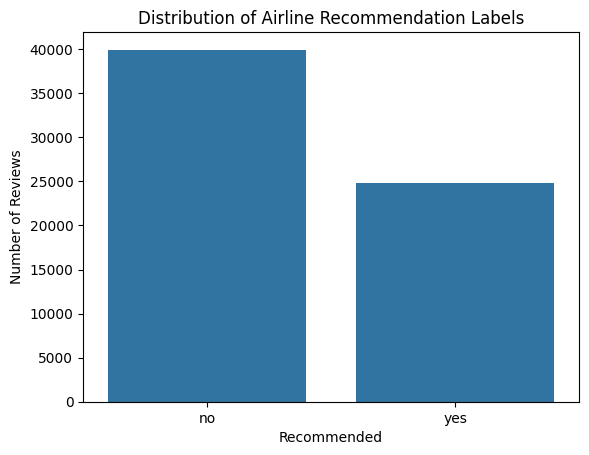

In [16]:
#Inspect the distribution of recommendation labels on the original dataset

counts = df_airline["recommended"].value_counts()

percentages = (df_airline["recommended"].value_counts(normalize=True) * 100).round(2)

# Combine into one DataFrame
recommended_distribution = pd.DataFrame({
    "Count": counts,
    "Percentage (%)": percentages
})

# Display side by side
print("\n**Distribution of the Recommendation Labels before cleaning**")
print(recommended_distribution)

# Visualize the target variable distribution
sns.countplot(data=df_airline, x="recommended")

plt.title("Distribution of Airline Recommendation Labels")
plt.xlabel("Recommended")
plt.ylabel("Number of Reviews")

plt.show()

In [17]:
#checking missing values
df_airline.isnull().sum()

,0
review_date,0
over_all_rating,116
review_header,0
trip_verified,11693
review_text,147
aircraft,36767
type_of_traveller,2638
seat_type,38
route,2861
date_flown,2736


In [18]:
#checking duplicated values
df_airline.duplicated().sum()

np.int64(64)

### **Data Inspection Findings**

The initial inspection of the airline passenger reviews dataset revealed that the dataset contains 64740 number of rows and 19 columns.Each row represents a passenger review,while the columns contain information about passenger experiences and airline services quality.

The column names and data types were examined to understand the structure of the dataset.The dataset contains numerical and categorical variables,including the overall rating,trip verification status,review text,aircraft,type of traveller,seat type,route and date flown.

The missing value analysis revealed that several columns contained missing values,with the wifi connectivity column having particularly high number of missing entries.Duplicate records were also examined to determine whether repeated entries could affect the analysis.

The statistical summary provided an overview of the numerical variables,including their central tendency and distribution.These findings  helped identify potential data quality issues that needed to be addressed during the data cleaning stage.

Overall, the inspection established the structure and quality of the dataset and identified missing values and possible duplicate records that required further investigation before exploratory data analysis and model development.

In [19]:
#Creating a backup of the original dataset
df_original = df_airline.copy()

# **3. Data Preparation**

## **3.1 Data Cleaning: Airline Reviews Dataset**





### **3.1.1 Missing Values**

Missing values occur when information is not recorded for a particular observation.

The initial inspection identified missing values in several columns.The reported counts include:
  
  -Overall rating:116 missing values.

  -Trip verified:11,693 missing values.

  -Review text: 147 missing values.

  -Aircraft:36767 missing values.

  -Type of traveler:2,638 missing values.

  -Seat type:38 missing values.

  -Route:2,861 missing values.

  -Date flown:2,736 missing values.

  -Seat comfort:3,475 missing values.

  -Cabin staff service:3,702 missing values.

  -Food beverages:12,591 missing values.

  -Inflight Entertainment: 21,162 missing values.

  -Ground service:4,687 missing values.

  -Wifi connectivity:41,118 missing values.

  -Value for money:22 missing values.

  -recommended:1 missing value.


  The treatment of missing values depends on the column.




In [20]:
#calculating the missing value count and percentage

missing_values = df_airline.isnull().sum()
missing_percentage = (df_airline.isnull().mean() * 100)

missing_summary = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage":missing_percentage
})
missing_summary = missing_summary.sort_values(
    by="Missing_Percentage",
    ascending=False
)
print(missing_summary.round(2))

                        Missing_Count  Missing_Percentage
wifi__connectivity              41118               63.51
aircraft                        36767               56.79
inflight_entertainment          21162               32.69
food__beverages                 12591               19.45
trip_verified                   11693               18.06
ground_service                   4687                7.24
cabin_staff_service              3702                5.72
seat_comfort                     3475                5.37
route                            2861                4.42
date_flown                       2736                4.23
type_of_traveller                2638                4.07
review_text                       147                0.23
over_all_rating                   116                0.18
seat_type                          38                0.06
value_for_money                    22                0.03
recommended                         1                0.00
review_date   

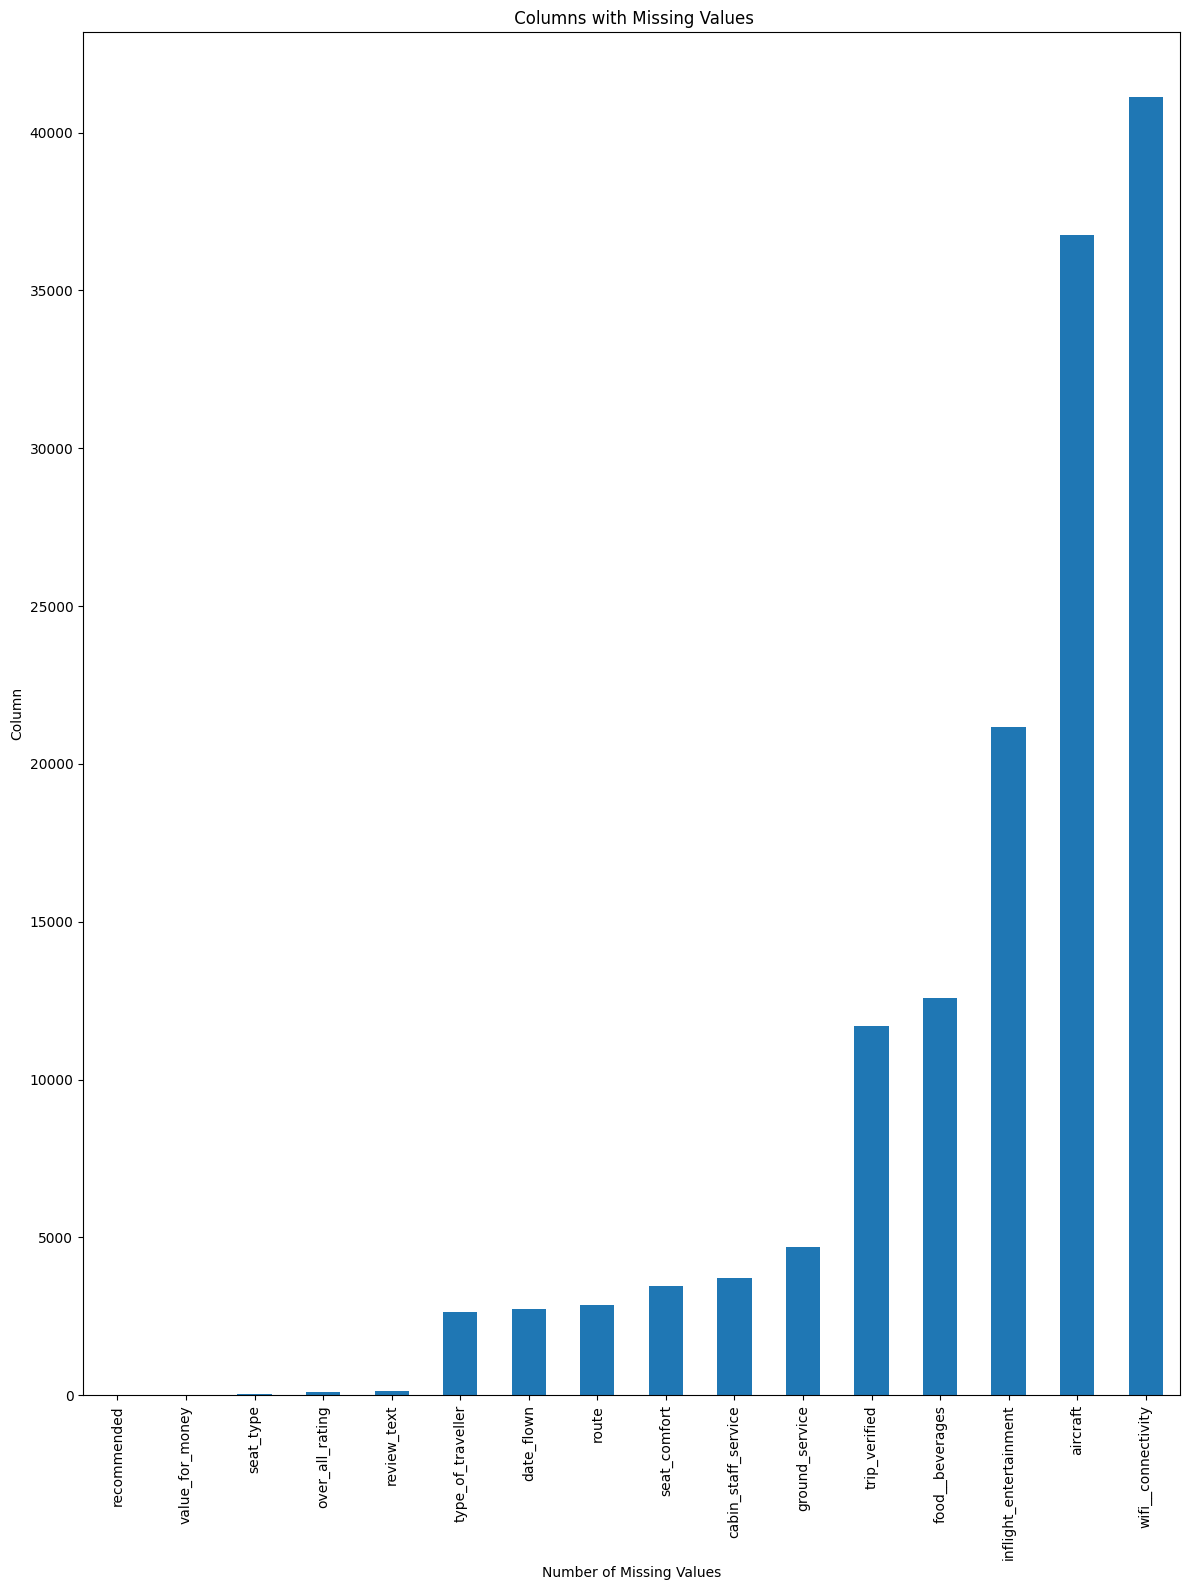

In [21]:
#visualize misssing values
missing_plot = missing_summary[
    missing_summary['Missing_Count'] > 0
].head(20)
plt.figure(figsize=(12,16))
missing_plot["Missing_Count"].sort_values().plot(kind="bar")
plt.title(" Columns with Missing Values")
plt.xlabel("Number of Missing Values")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [22]:
#Identify categorical and numerical columns
#display the data type of every column
print(df_airline.dtypes.to_frame(name="Data Type"))

#identify numerical columns
numerical_columns = df_airline.select_dtypes(include="number").columns.tolist()
#identify categorical and text columns
categorical_columns = df_airline.select_dtypes(include=['object','category','bool','string']).columns.tolist()

print("Numerical_columns:", numerical_columns)

print("Categorical Columns:", categorical_columns)

                       Data Type
review_date               object
over_all_rating          float64
review_header             object
trip_verified             object
review_text               object
aircraft                  object
type_of_traveller         object
seat_type                 object
route                     object
date_flown                object
seat_comfort             float64
cabin_staff_service      float64
food__beverages          float64
inflight_entertainment   float64
ground_service           float64
wifi__connectivity       float64
value_for_money          float64
recommended               object
airline_name              object
Numerical_columns: ['over_all_rating', 'seat_comfort', 'cabin_staff_service', 'food__beverages', 'inflight_entertainment', 'ground_service', 'wifi__connectivity', 'value_for_money']
Categorical Columns: ['review_date', 'review_header', 'trip_verified', 'review_text', 'aircraft', 'type_of_traveller', 'seat_type', 'route', 'date_flown', 're

In [23]:
#excluded the recommended and review text columns
excluded_columns = ['review_text','recommended']
#numerical columns to impute
numerical_columns_fill = [
    col for col in numerical_columns
    if col not in excluded_columns
]
#categorical columns to impute
categorical_columns_fill = [
col for col in categorical_columns
if col not in excluded_columns
]


print("Numerical columns to fill:")
print(numerical_columns_fill)

print("\nCategorical columns to fill:")
print(categorical_columns_fill)

Numerical columns to fill:
['over_all_rating', 'seat_comfort', 'cabin_staff_service', 'food__beverages', 'inflight_entertainment', 'ground_service', 'wifi__connectivity', 'value_for_money']

Categorical columns to fill:
['review_date', 'review_header', 'trip_verified', 'aircraft', 'type_of_traveller', 'seat_type', 'route', 'date_flown', 'airline_name']


In [24]:
#handling missing values in numerical columns

#converting the ratings to numeric values
for col in numerical_columns_fill:
  df_airline[col] = pd.to_numeric(df_airline[col],errors='coerce')

df_airline[numerical_columns_fill] = df_airline[numerical_columns_fill].fillna(df_airline[numerical_columns_fill].median())

In [25]:
#confirming
df_airline.isnull().sum()

,0
review_date,0
over_all_rating,0
review_header,0
trip_verified,11693
review_text,147
aircraft,36767
type_of_traveller,2638
seat_type,38
route,2861
date_flown,2736


In [26]:
#handling missing values in categorical columns
df_airline[categorical_columns_fill] = df_airline[categorical_columns_fill].fillna('Unknown')

In [27]:
#confirmation
df_airline.isnull().sum()

,0
review_date,0
over_all_rating,0
review_header,0
trip_verified,0
review_text,147
aircraft,0
type_of_traveller,0
seat_type,0
route,0
date_flown,0


In [28]:
#Handle missing values in recommended and review text column
df_airline = df_airline.dropna(subset=["review_text","recommended"])

In [29]:
#confirmation
df_airline.isnull().sum()

,0
review_date,0
over_all_rating,0
review_header,0
trip_verified,0
review_text,0
aircraft,0
type_of_traveller,0
seat_type,0
route,0
date_flown,0


In [30]:
df_airline.shape

(64592, 19)

### **3.1.2 Handling Duplicates**

Duplicate records are repeated observations in a dataset.They can affect analysis by giving repeated information more weight than intended.

We will first count the exact duplicate rows.We will then remove exact duplicates while keeping the first occurrence.

In [31]:
#removing duplicates
df_airline.drop_duplicates(inplace=True)

In [32]:
#confirming
df_airline.duplicated().sum()

np.int64(0)

In [33]:
df_airline.shape

(64528, 19)

### **3.1.3 Data Cleaning Summary and Justification**

Data Cleaning was performed to improve the quality and realibilty of the airline passenger reviews dataset before exploratory data analysis, text preprocessing and model development.The process focused on handling missing values and duplicate records while preserving useful information for the project.

***1.Handling Missing Values***

The dataset contained missing values in both numerical anad categorical columns.Different methods were selected depending on the data type and the purpose of each variable.

a.)**Numerical Columns**:Misiing values in numerical columns were handled using median imputation.The median was chosen because it is less sensitive to extreme values and outliers than mean,making it a suitable option for numerical variables such as service ratings.

b.)**Categorical Columns**:Missing values in the remaining categorical columns were replaced with "**Unknown**".This approach preserves records while explicitly indicating that information was unavailable,rather than assigning an unsupported category to the passsenger.

c.)**Review text column**: Missing and empty review texts were removed because the project uses passenger reviews as input features for BERT and DistilBERT.Filling missing reviews with 'Unkown" would introduce text that does not represent an actual passenger experience and could negatively affect model learning.

d.)**Recommended column**:Rows with missing recommendation labels were removed  because the recommendation column is the target variable for the binary classification task.Imputing these values could introduce incorrect labels and mislead the models during training.

The review text and recommendation columns were therefore excluded from general numerical and categorical imputation and handled separately.


***2.Handling Duplicate Records***

Duplicate records were checked and handled to reduce unnecessary repetition in the dataset.

Exact duplicates rows were removed because repeated copies of the same record can give certain observations disproportionate influence during analysis and model training.Removing such duplicates helps reduce redundancy and produces a more reliable dataset.



***3.Verification After Cleaning***

After Handling missing values and duplicates,the dataset was checked again to assess the results of the cleaning operations.The remaining missing values,empty reviews,duplicate records,and the dataset dimensions were examined to verify the quality of the resulting data.

**Conclusion**

These decisions prepared the dataset for exploratory data analysis,text preprocessing, and the development of BERT and DistilBERT models to predict airline passenger recommendations.


## **3.2 Text Preprocessing for Airline Data**



In [34]:
#creating the preprocessing tools
stop_words = set(stopwords.words('english'))
porter_stemmer = PorterStemmer()
snowball_stemmer = SnowballStemmer('english')
lemmatizer = WordNetLemmatizer()

# creating the preprocess_text function

def preprocess_text(text):
  if not isinstance(text,str):
    return[]
  #convert to lowercase
  text = text.lower()
  #removes url
  text = re.sub(r'http\s+|www\s+','',text)
  #tokenization
  sentence = sent_tokenize(text)
  tokens =word_tokenize(text)
  #keep alphabets only
  tokens = [word for word in tokens if word.isalpha()]
  #remove stopwords
  tokens = [word for word in tokens if word not in stop_words]
  #lemmatize the tokens
  tokens = [lemmatizer.lemmatize(word) for word in tokens]
  return tokens

In [35]:
# Apply pre-processing
df_airline['processed_tokens'] = df_airline['review_text'].apply(preprocess_text)
df_airline['processed_tokens'].head()

,processed_tokens
0,"[afternoon, flight, delayed, eventually, flew,..."
1,"[flight, postponed, time, insufficient, explan..."
2,"[charge, hand, baggage, exceeds, including, la..."
3,"[flight, delayed, passed, air, india, ticket, ..."
4,"[crowd, control, boarding, like, cattle, herde..."


# **4. Modeling**

## **4.1 Classification: Term Frequency, Inverse Document Frequency Model (TF-IDF)**

We will use TF-IDF and logistic regression features as our base model for text classification.This model is a numerical representation of text that reflects the importance of a word in a document relative to a collection of documents. It helps to highlight words that are more relevant to the specific document while downplaying common words that appear frequently across all documents.


In [36]:
# Libraries for tf-idf vectorization and model building
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

### **4.1.1 Prepare the Airlines dataset for Modeling**

The y target variable sufficient for this model is the column [recommended], whereby reviewers give a yes or no answer.
We will inspect and visualize the distribution of this target variable.

The X feature for this model will be the processed [review_text], labeled her as [processed_text], which contains a string of text reviews input by passengers.


In [37]:
# Prepare the preprocessed text for TF-IDF

# Convert lists of tokens into strings
df_airline["processed_text"] = df_airline["processed_tokens"].apply(
    lambda tokens: " ".join(tokens)
    if isinstance(tokens, list) else tokens
)

display(
    df_airline[
        ["review_text", "processed_tokens", "processed_text"]
    ].head()
)

,review_text,processed_tokens,processed_text
0,My afternoon flight was delayed and eventuall...,"[afternoon, flight, delayed, eventually, flew,...",afternoon flight delayed eventually flew pm co...
1,The flight was postponed 3 times with insuffi...,"[flight, postponed, time, insufficient, explan...",flight postponed time insufficient explanation...
2,They will charge you for your hand baggage if...,"[charge, hand, baggage, exceeds, including, la...",charge hand baggage exceeds including laptop g...
3,The flight was delayed from 15:20 to 16:25. I...,"[flight, delayed, passed, air, india, ticket, ...",flight delayed passed air india ticket could a...
4,No crowd control and boarding was like cattle...,"[crowd, control, boarding, like, cattle, herde...",crowd control boarding like cattle herded insi...


In [38]:
# Select columns for tf-idf model
tfidf_model = df_airline[["processed_text", "recommended"]].copy()

display(tfidf_model.head())
print("\nModeling dataset shape:", tfidf_model.shape)

,processed_text,recommended
0,afternoon flight delayed eventually flew pm co...,no
1,flight postponed time insufficient explanation...,no
2,charge hand baggage exceeds including laptop g...,no
3,flight delayed passed air india ticket could a...,no
4,crowd control boarding like cattle herded insi...,no



Modeling dataset shape: (64528, 2)



**Distribution of the Target Variable**
             Count  Percentage (%)
recommended                       
no           39819           61.71
yes          24709           38.29


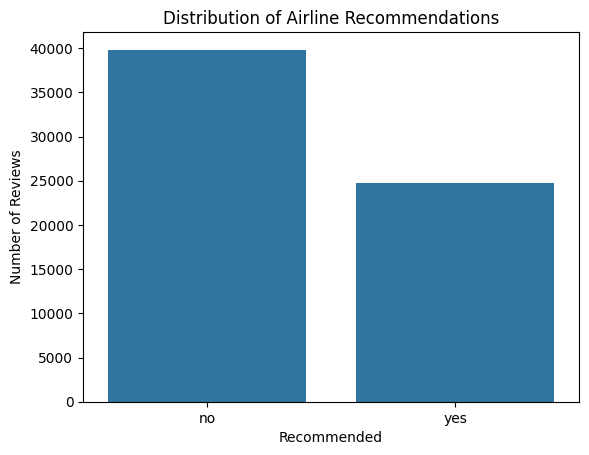

In [39]:
#Inspect the target variable, [recommended]

counts = tfidf_model["recommended"].value_counts()

percentages = (tfidf_model["recommended"].value_counts(normalize=True) * 100).round(2)

# Combine into one DataFrame
target_distribution = pd.DataFrame({
    "Count": counts,
    "Percentage (%)": percentages
})

# Display side by side
print("\n**Distribution of the Target Variable**")
print(target_distribution)

# Visualize the target variable distribution
sns.countplot(data=tfidf_model, x="recommended")

plt.title("Distribution of Airline Recommendations")
plt.xlabel("Recommended")
plt.ylabel("Number of Reviews")

plt.show()

### **4.1.2 Split the dataset into training and testing sets**

We will use an 80:20 split sets whereby 80% is for training data and 20% for testing data.


We will also use stratify=y to preserve the recommendation class distribution in both sets.

In [40]:
# Define X and y
X = tfidf_model["processed_text"]
y = tfidf_model["recommended"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)





### **4.1.3 Build the TF-IDF + Logistic Regression pipeline**

The TF-IDF vectorizer will be configured with a maximum of 50,000 vocabulary features and an n-gram range of (1,2) to capture both individual words and two-word phrases. The bigrams e.g 'delayed flight' provide more context compared to one word such as 'flight' or 'delayed'  

The min_df=2 parameter excludes words appearing in fewer than two documents, while max_df=0.95 removes terms occurring in more than 95% of reviews.

Additionally, sublinear_tf=True applies logarithmic scaling to term frequency, reducing the influence of frequently repeated words.

Logistic Regression will be configured with max_iter=1000 to allow sufficient iterations for model convergence.

In [41]:
tfidf_baseline_model = Pipeline([

    ("tfidf", TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),

    ("logreg", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))

])

### **4.1.4 Train the baseline model and make predictions**


In this stage, the pipeline automatically:

1. Learns the TF-IDF vocabulary from X_train.

2. Converts training reviews into TF-IDF vectors.

3. Trains Logistic Regression on the vectors and recommendation labels.

4. Makes prediction on recommendation labels

In [42]:
# Train the model
tfidf_baseline_model.fit(X_train, y_train)
print("Baseline model training completed!")

Baseline model training completed!


In [43]:
# Predict recommendation labels
y_pred = tfidf_baseline_model.predict(X_test)

# Check predictions probability
y_proba = tfidf_baseline_model.predict_proba(X_test)

print(tfidf_baseline_model.classes_)
print(y_proba[:5])

['no' 'yes']
[[0.39950108 0.60049892]
 [0.9754793  0.0245207 ]
 [0.94353928 0.05646072]
 [0.90046245 0.09953755]
 [0.96308684 0.03691316]]


### **4.1.5 Evaluation of the baseline model**




#### Check for accuracy, precision, recall, f1-score

In [44]:
#Evaluation metrics
tfidf_accuracy = accuracy_score(y_test, y_pred)
print("TF-IDF Baseline Accuracy:", tfidf_accuracy)

tfidf_precision = precision_score(
    y_test, y_pred, pos_label="yes"
)
print("TF-IDF Baseline Precision:", tfidf_precision)

tfidf_recall = recall_score(
    y_test, y_pred, pos_label="yes"
)
print("TF-IDF Baseline Recall:", tfidf_recall)

tfidf_f1 = f1_score(
    y_test, y_pred, pos_label="yes"
)
print("TF-IDF Baseline F1-Score:", tfidf_f1)
print()

print(classification_report(y_test, y_pred))

TF-IDF Baseline Accuracy: 0.9250736091740276
TF-IDF Baseline Precision: 0.9146672230335906
TF-IDF Baseline Recall: 0.8870902468636179
TF-IDF Baseline F1-Score: 0.9006676938880329

              precision    recall  f1-score   support

          no       0.93      0.95      0.94      7964
         yes       0.91      0.89      0.90      4942

    accuracy                           0.93     12906
   macro avg       0.92      0.92      0.92     12906
weighted avg       0.92      0.93      0.92     12906



#### Confusion Matrix

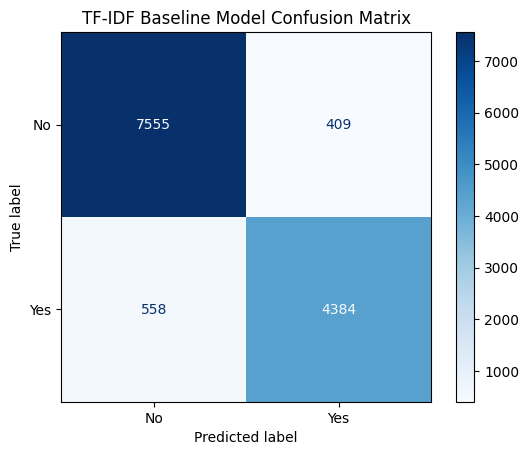

In [45]:
# Confusion Matrix
tfidf_confusion_matrix = confusion_matrix(
    y_test,
    y_pred,
    labels=["no", "yes"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=tfidf_confusion_matrix,
    display_labels=["No", "Yes"]
)

disp.plot(cmap="Blues")

plt.title("TF-IDF Baseline Model Confusion Matrix")
plt.show()

The confusion matrix shows that the TF-IDF baseline model correctly classified 7,567 reviews as non-recommendations (No) and 4,379 reviews as recommendations (Yes). However, it incorrectly classified 397 non-recommendation reviews as positive recommendations and 563 positive recommendation reviews as non-recommendations. Overall, the model correctly classified 12,013 out of 12,906 reviews, demonstrating strong classification performance. The higher number of false negatives (563) compared to false positives (397) indicates that the model was more likely to miss actual positive recommendations than incorrectly predict them.

#### ROC-AUC
**(Receiver Operating Characteristic – Area Under the Curve)**

ROC-AUC will measure how well the model distinguishes between reviews that are recommending and those that are not recommending airlines across classification thresholds.

In [46]:
# Find the probability column corresponding to "yes"
tfidf_yes_index = list(tfidf_baseline_model.classes_).index("yes")

tfidf_proba_yes = y_proba[:, tfidf_yes_index]

# Convert actual labels to binary
tfidf_test_binary = (y_test == "yes").astype(int)

tfidf_roc_auc = roc_auc_score(
    tfidf_test_binary,
    tfidf_proba_yes
)

print("TF-IDF ROC-AUC:", tfidf_roc_auc)

TF-IDF ROC-AUC: 0.9731102791375436


#### TF-IDF_baseline_results = pd.DataFrame({


In [47]:
tfidf_baseline_results = pd.DataFrame({
    "Model": ["TF-IDF + Logistic Regression"],
    "Accuracy": [tfidf_accuracy],
    "Precision": [tfidf_precision],
    "Recall": [tfidf_recall],
    "F1 Score": [tfidf_f1],
    "ROC-AUC": [tfidf_roc_auc]
})

tfidf_baseline_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,TF-IDF + Logistic Regression,0.925074,0.914667,0.88709,0.900668,0.97311


The TF-IDF baseline model using Logistic Regression features achieved an overall accuracy of 93.08%. This shows that it correctly classified approximately 93 out of every 100 airline reviews in the test dataset.

The model has a precision of 92.58%, this suggests that about 93% of reviews predicted as recommending an airline were correctly classified as positive recommendations.

A recall of 89.07% shows that it successfully identified about 89% of all actual positive recommendations, while missing around 11% of them.

The F1-score of 90.79% shows a strong balance between precision and recall for the positive recommendation class.

The classification report further indicates that the model performed slightly better in identifying passengers who did not recommend airlines (no), achieving a precision of 93%, recall of 96%, and F1-score of 94%, compared to the positive recommendation class (yes), which achieved 93% precision, 89% recall, and 91% F1-score.

Although the model achieves high accuracy, its positive-class recall of 89.07% suggests that some passengers who recommend airlines are incorrectly classified as non-recommenders. Further evaluation, particularly through a confusion matrix and comparison with DistilBERT, can check whether this performance can be improved.

### **4.1.6 Test TF-IDF+Log model on new information**

These sample reviews are copied from actual customer reviews on tripadvisor.com for Kenya Airways (https://www.tripadvisor.com/Airline_Review-d8729102-Reviews-Kenya-Airways)

In [48]:
#Copy sample reviews for prediction
new_reviews = [
    "Terrible Customer Service, Misleading Information, and Unacceptable Refund Delays!.",
    "Fly Kenya Airways if you do not have any option",
    "Never Again - terrible airline.",
    "Flight went on time, checked baggage went and received at the end with no damage, service was good and heating was on onboard which is all I really ask for. Just 1 thing could be better is legroom, Just 2 inches more could make a massive difference in having more repeat customers."
    "My first experience flying with an African airline was, regrettably, a profound disappointment."
]

predictions = tfidf_baseline_model.predict(new_reviews)

probabilities = tfidf_baseline_model.predict_proba(new_reviews)

for review, prediction, probability in zip(
    new_reviews,
    predictions,
    probabilities
):
    print("Review:", review)
    print("Predicted recommendation:", prediction)
    print("Probabilities:", probability)
    print("-" * 60)

Review: Terrible Customer Service, Misleading Information, and Unacceptable Refund Delays!.
Predicted recommendation: no
Probabilities: [0.99672322 0.00327678]
------------------------------------------------------------
Review: Fly Kenya Airways if you do not have any option
Predicted recommendation: no
Probabilities: [0.72940132 0.27059868]
------------------------------------------------------------
Review: Never Again - terrible airline.
Predicted recommendation: no
Probabilities: [0.99853882 0.00146118]
------------------------------------------------------------
Review: Flight went on time, checked baggage went and received at the end with no damage, service was good and heating was on onboard which is all I really ask for. Just 1 thing could be better is legroom, Just 2 inches more could make a massive difference in having more repeat customers.My first experience flying with an African airline was, regrettably, a profound disappointment.
Predicted recommendation: yes
Probabilit

**4.2.7 Extract feature words from the TF-IDF learning**

In [49]:
# Extract TF-IDF feature names
tfidf = tfidf_baseline_model.named_steps["tfidf"]

# Extract Logistic Regression coefficients
logreg = tfidf_baseline_model.named_steps["logreg"]

feature_names = tfidf.get_feature_names_out()

coefficients = logreg.coef_[0]

# Create a DataFrame
feature_importance = pd.DataFrame({
    "word": feature_names,
    "coefficient": coefficients
})

feature_importance.head(20)

,word,coefficient
0,aa,-1.244191
1,aa advantage,-0.044470
2,aa agent,0.094496
3,aa airline,0.103967
4,aa app,-0.109992
5,aa baggage,-0.042089
6,aa care,-0.050942
7,aa changed,-0.087120
8,aa could,0.064137
9,aa counter,-0.043890


#### Strongest feature words

In [50]:
# Strongest terms for positive recommendations
top_positive = feature_importance.sort_values(
    "coefficient",
    ascending=False
).head(20)

top_positive

,word,coefficient
15382,excellent,9.846047
20847,good,9.361537
21364,great,8.351844
43735,thank,8.228438
9323,comfortable,6.677471
19368,friendly,5.723533
2541,amazing,5.692123
30135,nice,5.511492
34841,professional,5.244681
41084,smooth,5.162168


#### Weakest feature words

In [51]:
# Strongest terms for negative recommendations
top_negative = feature_importance.sort_values(
    "coefficient",
    ascending=True
).head(20)

top_negative

,word,coefficient
49380,worst,-7.745003
29816,never,-7.298858
37414,rude,-6.669687
34132,poor,-6.370269
43672,terrible,-5.848263
45120,told,-5.636906
46635,uncomfortable,-5.485827
22490,horrible,-5.363005
4283,avoid,-5.043245
32795,pay,-4.650991


#### Visualization of top feature words

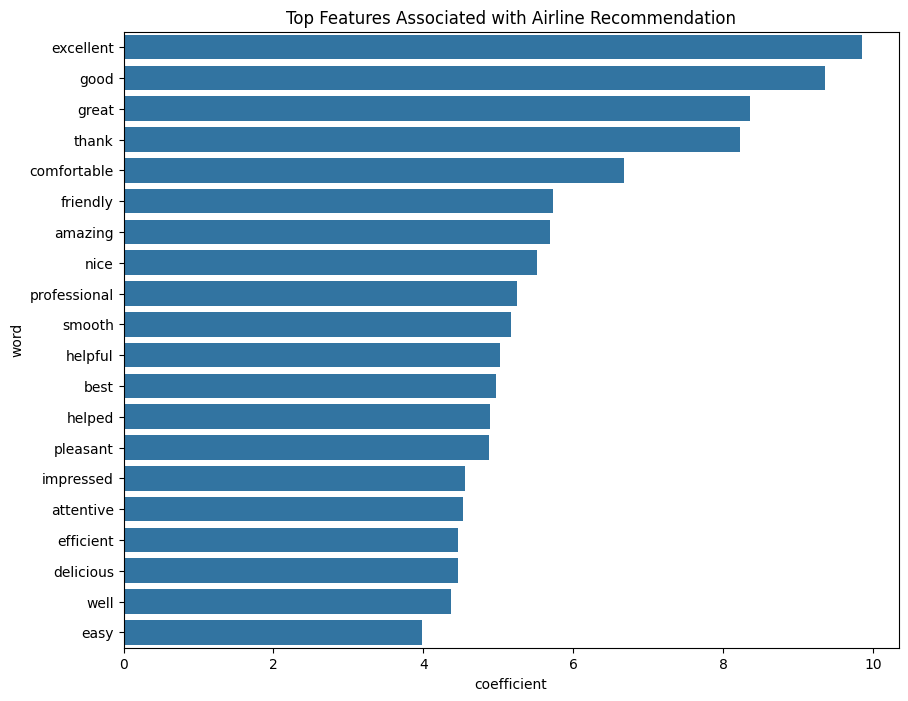

In [52]:
# Visualize the top positive features
plt.figure(figsize=(10, 8))

sns.barplot(
    data=top_positive,
    x="coefficient",
    y="word"
)

plt.title("Top Features Associated with Airline Recommendation")
plt.show()

### **4.1.7 Save the tf-idf baseline model to load later when needed**

We can save the baseline model for a possibility to load it later and use it in a future Streamlit or Flask application.

In [53]:
# Save the tfidf baseline model
import joblib

joblib.dump(tfidf_baseline_model, "tfidf_baseline_model.pkl")

['tfidf_baseline_model.pkl']

In [54]:
# Load it later
tfidf_baseline_model = joblib.load("tfidf_baseline_model.pkl")


## **4.2 Advanced deep learning modeling with DistilBert**

DistilBERT is a smaller, faster version of BERT, a transformer-based language model developed for understanding text.

DistilBERT will use the surrounding words to interpret expressions such as "not good" and "but the crew was excellent." to create a contextual learning.

This model uses the cleaned skytrax airline dataset but does not need the text pre-processing pipeline to retain complete sentence structure and negation.

We will fine tune the pre-trained model to predict the same target variable on our airline reviews data used in the baseline model.

For fair comparison, we will use the same train/test split.

We will evaluate accuracy, precision, recall, F1-score and ROC-AUC, and plot a confusion matrix.

We will also test the model on new airline reviews.

We shall compare DistilBERT with TF-IDF + Logistic Regression.

It is not guaranteed that this transformer model will outperform the TF-IDF logistic regression baseline model.

Finally, we will save the fine-tuned model and tokenizer for future use.

In [55]:
#!pip install -q -U transformers datasets accelerate scikit-learn matplotlib seaborn

### **4.2.1 Check Runtime Settings**

DistilBERT is computationally demanding and we therefore need the Runtime to be GPU if available. However, training the transformer on a CPU runtime is possible but considerably slower.

In [56]:
import torch

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    DataCollatorWithPadding,
    set_seed
)

set_seed(42)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


### **4.2.2 Prepare the dataset for DistilBert Modeling**

We will use the same two columns as the baseline model:

- review_text as the input feature.
- recommended as the target label (no or yes) which will be encoded to (0 and 1) respectively.

#### Label encoding

In [57]:
# Use the cleaned reviews DataFrame
distilbert_df = df_airline[["review_text", "recommended"]].copy()

print(distilbert_df.shape)

# Convert labels to numerical values
distilbert_df["label"] = (
    distilbert_df["recommended"]
    .map({"no": 0, "yes": 1})
)

print(distilbert_df["label"].value_counts())

display(distilbert_df.head())

(64528, 2)
label
0    39819
1    24709
Name: count, dtype: int64


,review_text,recommended,label
0,My afternoon flight was delayed and eventuall...,no,0
1,The flight was postponed 3 times with insuffi...,no,0
2,They will charge you for your hand baggage if...,no,0
3,The flight was delayed from 15:20 to 16:25. I...,no,0
4,No crowd control and boarding was like cattle...,no,0


Neural network classifiers will require numerical target labels. We assign 0 to passengers who do not recommend the airline and 1 to passengers who recommend it.

Unlike TF-IDF, DistilBERT doesn't need unnecessary cleaning like stemming and lematization because sentence structure and negation carry important meaning.

#### Define variables and Split datasets into train and test sets

In [58]:
# Define X and y
X_bert = distilbert_df["review_text"]
y_bert = distilbert_df["label"].astype(int)



# Split the dataset into training and testing sets
X_train_bert, X_test_bert, y_train_bert, y_test_bert = train_test_split(
    X_bert, y_bert, test_size=0.2, random_state=42, stratify=y_bert
)

# Split training data into training and validation sets
X_train_bert, X_val_bert, y_train_bert, y_val_bert = train_test_split(
    X_train_bert,
    y_train_bert,
    test_size=0.1,
    random_state=42,
    stratify=y_train_bert
)

print("Training samples:", len(X_train_bert))
print("Validation samples:", len(X_val_bert))
print("Testing samples:", len(X_test_bert))

Training samples: 46459
Validation samples: 5163
Testing samples: 12906


#### Convert data into Hugging Face datasets


In [59]:
# Convert data into Hugging Face datasets

def make_dataset(texts, labels):
    return Dataset.from_dict({
        "text": pd.Series(texts).astype(str).tolist(),
        "labels": pd.Series(labels).astype(int).tolist()
    })

train_dataset = make_dataset(X_train_bert, y_train_bert)
val_dataset = make_dataset(X_val_bert, y_val_bert)
test_dataset = make_dataset(X_test_bert, y_test_bert)

print("\nTraining dataset:",train_dataset)
print("\nValidation dataset:",val_dataset)
print("\nTest dataset:",test_dataset)


Training dataset: Dataset({
    features: ['text', 'labels'],
    num_rows: 46459
})

Validation dataset: Dataset({
    features: ['text', 'labels'],
    num_rows: 5163
})

Test dataset: Dataset({
    features: ['text', 'labels'],
    num_rows: 12906
})


### **4.2.3 Hugging face pre-trained model**

#### Load the DistilBert tokenizer

In [66]:
# Load the DistilBert tokenizer


# Load the DistilBERT tokenizer

model_bert = "distilbert/distilbert-base-uncased"

bert_tokenizer = AutoTokenizer.from_pretrained(model_bert)

# Define tokenization function
def bert_tokenize_reviews(batch):
    return bert_tokenizer(
        batch["text"],
        truncation=True,
        max_length=256
    )

# Tokenize training dataset
bert_train_tokenized = train_dataset.map(
    bert_tokenize_reviews,
    batched=True
)

# Tokenize validation dataset
bert_val_tokenized = val_dataset.map(
    bert_tokenize_reviews,
    batched=True
)

# Tokenize test dataset
bert_test_tokenized = test_dataset.map(
    bert_tokenize_reviews,
    batched=True
)

# Create data collator
bert_data_collator = DataCollatorWithPadding(
    tokenizer=bert_tokenizer
)

# Confirm tokenization
print("DistilBERT tokenization completed successfully!")

print("\nTokenized training dataset:", bert_train_tokenized)
print("\nTokenized validation dataset:", bert_val_tokenized)
print("\nTokenized test dataset:", bert_test_tokenized)


Map:   0%|          | 0/46459 [00:00<?, ? examples/s]

Map:   0%|          | 0/5163 [00:00<?, ? examples/s]

Map:   0%|          | 0/12906 [00:00<?, ? examples/s]

DistilBERT tokenization completed successfully!

Tokenized training dataset: Dataset({
    features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 46459
})

Tokenized validation dataset: Dataset({
    features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 5163
})

Tokenized test dataset: Dataset({
    features: ['text', 'labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 12906
})


#### Load pretrained Distilbert

In [69]:

# Load Pretrained DistilBERT Model

# Map numerical labels to recommendation classes
bert_id2label = {
    0: "no",
    1: "yes"
}

# Map recommendation classes to numerical labels
bert_label2id = {
    "no": 0,
    "yes": 1
}

# Load pretrained DistilBERT for binary classification
pretrained_bert = AutoModelForSequenceClassification.from_pretrained(
    model_bert,
    num_labels=2,
    id2label=bert_id2label,
    label2id=bert_label2id
)

print("DistilBERT model loaded successfully.")
print("Model architecture:", pretrained_bert.config.model_type)
print("Number of labels:", pretrained_bert.config.num_labels)
print("Label mapping:", pretrained_bert.config.id2label)


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBERT model loaded successfully.
Model architecture: distilbert
Number of labels: 2
Label mapping: {0: 'no', 1: 'yes'}


#### Define evaluation metrics for the model

In [70]:
# Create function to define evaluation metrics for the Hugging Face Transformer


def bert_compute_metrics(eval_pred):
    logits, labels = eval_pred

    probabilities = torch.softmax(
        torch.tensor(logits), dim=1
    ).numpy()[:, 1]

    predictions = np.argmax(logits, axis=1)

    results = {
        "accuracy": accuracy_score(labels, predictions),
        "precision": precision_score(
            labels, predictions, zero_division=0
        ),
        "recall": recall_score(
            labels, predictions, zero_division=0
        ),
        "f1": f1_score(
            labels, predictions, zero_division=0
        )
    }

    if len(np.unique(labels)) == 2:
        results["roc_auc"] = roc_auc_score(
            labels, probabilities
        )

    return results


#### Configure training arguments for the model

We will begin with two epochs, a learning rate of 2e-5, and a batch size of 8.

In [71]:
# Configure training arguments for the Hugging Face Transformer

bert_training_args = TrainingArguments(
    output_dir="./distilbert_airline_results",

    num_train_epochs=2,
    learning_rate=2e-5,

    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,

    weight_decay=0.01,
    warmup_steps=0.1,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    save_total_limit=2,
    logging_steps=100,

    fp16=torch.cuda.is_available(),
    report_to="none",
    seed=42
)


### **4.2.4 Train the model**

In [73]:
# Initialize the Hugging Face Trainer


# Initialize the Hugging Face Trainer

bert_trainer = Trainer(
    model=pretrained_bert,
    args=bert_training_args,

    train_dataset=bert_train_tokenized,
    eval_dataset=bert_val_tokenized,

    processing_class=bert_tokenizer,
    data_collator=bert_data_collator,

    compute_metrics=bert_compute_metrics
)

print("DistilBERT Trainer initialized successfully.")


DistilBERT Trainer initialized successfully.


### **4.2.5 Fine tune the model**

In [74]:
#  Fine-tune DistilBERT

bert_train_result = bert_trainer.train()

print("DistilBERT fine-tuning completed successfully.")

Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1,Roc Auc
1,0.237884,0.242173,0.923107,0.866080,0.945372,0.903990,0.980491
2,0.123064,0.291505,0.933953,0.926042,0.899342,0.912497,0.978939


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT fine-tuning completed successfully.


### **4.2.6 Evaluate the fine-tuned model**

#### Final metrics to compare with the baseline model

In [76]:
#Evaluate the Fine-Tuned DistilBERT Model

bert_test_results = bert_trainer.evaluate(
    eval_dataset=bert_test_tokenized,
    metric_key_prefix="test"
)

# Display evaluation metrics
print("\nDistilBERT Test Evaluation Results:\n")

for metric, value in bert_test_results.items():
    if isinstance(value, (int, float)):
        print(f"{metric}: {value:.4f}")


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1,Roc Auc
0.123064,0.254765,2,0.942817,0.934657,0.914609,0.924524,0.981444



DistilBERT Test Evaluation Results:

test_loss: 0.2548
test_accuracy: 0.9428
test_precision: 0.9347
test_recall: 0.9146
test_f1: 0.9245
test_roc_auc: 0.9814


#### Classification report

In [77]:

# Generate DistilBERT Classification Report

# Generate predictions on the test dataset
bert_pred_output = bert_trainer.predict(bert_test_tokenized)

# Extract logits and actual labels
bert_logits = bert_pred_output.predictions
bert_y_true = bert_pred_output.label_ids

# Convert logits to predicted class labels
bert_y_pred = np.argmax(bert_logits, axis=1)

# Convert logits to probabilities for the positive class (yes = 1)
bert_y_prob = torch.softmax(
    torch.tensor(bert_logits), dim=1
).numpy()[:, 1]

# Generate classification report
print("\nDistilBERT Classification Report:\n")

print(
    classification_report(
        bert_y_true,
        bert_y_pred,
        labels=[0, 1],
        target_names=["no", "yes"],
        digits=4,
        zero_division=0
    )
)



DistilBERT Classification Report:

              precision    recall  f1-score   support

          no     0.9477    0.9603    0.9540      7964
         yes     0.9347    0.9146    0.9245      4942

    accuracy                         0.9428     12906
   macro avg     0.9412    0.9375    0.9392     12906
weighted avg     0.9427    0.9428    0.9427     12906



#### DistilBert Confusion Matrix

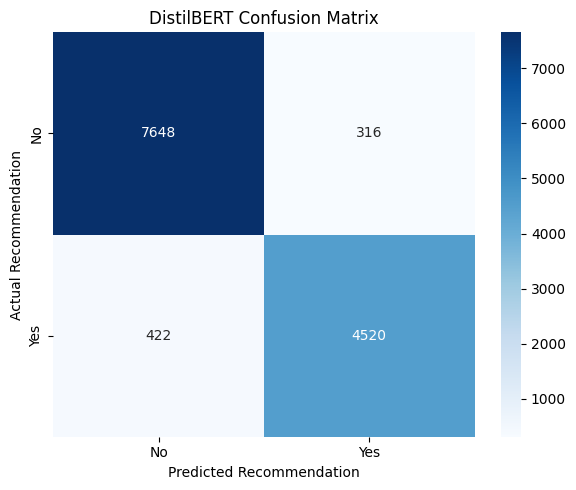

In [78]:
#Distilbert Confusion Matrix
bert_cm = confusion_matrix(bert_y_true, bert_y_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    bert_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("DistilBERT Confusion Matrix")
plt.xlabel("Predicted Recommendation")
plt.ylabel("Actual Recommendation")
plt.tight_layout()
plt.show()

Distilbert evaluation results

In [89]:
bert_results = pd.DataFrame({
    "Model": ["DistilBERT"],
    "Accuracy": [bert_test_results["test_accuracy"]],
    "Precision": [bert_test_results["test_precision"]],
    "Recall": [bert_test_results["test_recall"]],
    "F1 Score": [bert_test_results["test_f1"]],
    "ROC-AUC": [bert_test_results["test_roc_auc"]]
})
display(bert_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,DistilBERT,0.9428,0.9347,0.9146,0.9245,0.9814


### **4.2.7 Test DistilBERT on new airline reviews**

In [83]:
# Sample airline reviews
bert_sample_reviews = [
    "Terrible Customer Service, Misleading Information, and Unacceptable Refund Delays!.",
    "Fly Kenya Airways if you do not have any option",
    "Never Again - terrible airline.",
    "Flight went on time, checked baggage went and received at the end with no damage, service was good and heating was on onboard which is all I really ask for. Just 1 thing could be better is legroom, Just 2 inches more could make a massive difference in having more repeat customers."
    "My first experience flying with an African airline was, regrettably, a profound disappointment."
]

# Set the fine-tuned model to evaluation mode
bert_model = bert_trainer.model
bert_model.eval()

# Tokenize sample reviews
bert_inputs = bert_tokenizer(
    bert_sample_reviews,
    padding=True,
    truncation=True,
    max_length=256,
    return_tensors="pt"
)

# Move inputs to the same device as the model
bert_inputs = {
    key: value.to(bert_model.device)
    for key, value in bert_inputs.items()
}

# Generate predictions without calculating gradients
with torch.no_grad():
    bert_outputs = bert_model(**bert_inputs)

# Convert logits to class probabilities
bert_probabilities = torch.softmax(
    bert_outputs.logits, dim=1
).cpu().numpy()

# Extract predicted classes
bert_predictions = np.argmax(
    bert_probabilities, axis=1
)

# Create a DataFrame of prediction results
bert_results_df = pd.DataFrame({
    "Review": bert_sample_reviews,
    "Predicted Recommendation": [
        bert_id2label[int(p)] for p in bert_predictions
    ],
    "Confidence": bert_probabilities.max(axis=1)
})

# Add probability columns
bert_results_df["Probability (No)"] = bert_probabilities[:, 0]
bert_results_df["Probability (Yes)"] = bert_probabilities[:, 1]

# Round numerical values
bert_results_df = bert_results_df.round(4)

bert_results_df




,Review,Predicted Recommendation,Confidence,Probability (No),Probability (Yes)
0,"Terrible Customer Service, Misleading Informat...",no,0.9990,0.9990,0.0010
1,Fly Kenya Airways if you do not have any option,no,0.9703,0.9703,0.0297
2,Never Again - terrible airline.,no,0.9992,0.9992,0.0008
3,"Flight went on time, checked baggage went and ...",yes,0.9920,0.0080,0.9920


### **4.2.8 DistilBERT vs TF-IDF + Logistic Regression**

In [90]:

# Compare TF-IDF + Logistic Regression vs DistilBERT

model_comparison_df = pd.concat(
    [tfidf_baseline_results, bert_results],
    ignore_index=True
)

print("Model Performance Comparison:")
display(model_comparison_df.round(4))



Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,TF-IDF + Logistic Regression,0.9251,0.9147,0.8871,0.9007,0.9731
1,DistilBERT,0.9428,0.9347,0.9146,0.9245,0.9814


## **4.3 Model Performance Comparison**

DistilBERT shows higher performance across all five evaluation metrics in predicting airline passenger recommendations from textual reviews.
The baseline model achieved an accuracy of 92.51%, precision of 91.47%, recall of 88.71%, F1-score of 90.07%, and ROC-AUC of 97.31%. In comparison, DistilBERT achieved an accuracy of 94.28%, precision of 93.47%, recall of 91.46%, F1-score of 92.45%, and ROC-AUC of 98.14%.

DistilBERT had an accuracy improvement of 1.77% and a precision improvement of 2.%. It was more effective at correctly classifying airline reviews and reducing false positive predictions. Also, recall improved by 2.75%, showing more success in identifying passengers who truly recommended an airline. The F1-score increased by 2.38%, to indicate a stronger balance between precision and recall. The ROC-AUC also improved from 97.31% to 98.14%, to mean that DistilBERT differentiates between passengers who recommended an airline and those who did not better than the baseline model.

The improved performance of DistilBERT may be attributed to its transformer-based architecture, which captures contextual relationships and semantic meaning within review text more effectively than traditional TF-IDF representations. While TF-IDF + Logistic Regression relies primarily on statistical patterns in word occurrences, DistilBERT can account for word context, sentence structure, and more complex linguistic expressions, including negation and mixed sentiment. These capabilities are particularly valuable when analyzing airline reviews, where passengers frequently express both positive and negative experiences within the same review.

 DistilBERT seems to be the stronger-performing model for airline passenger recommendation classification based on the reported evaluation results. However, the TF-IDF + Logistic Regression model is a competitive baseline, with strong predictive performance, lower computational requirements and greater interpretability. Despite the measurable improvements of DistilBert, the benefits of TF-IDF makes it a computationally efficient alternative.